# Space Science — From the Moon to the Outer Solar System

Once a vehicle leaves the atmosphere, navigation becomes orbital mechanics. Two
questions drive every mission: where are the planets, and which path between them
costs the least propellant?

The notebook starts with the simplest estimate, a Hohmann transfer. It ends with a
spacecraft cruising under the gravity of the Sun and the planets, while an Extended
Kalman Filter (EKF) tracks it and a controller corrects its course.

| Step | Topic |
|------|-------|
| 1 | Coasting to the Moon and back |
| 2 | Earth to Mars: Hohmann estimate, launch-window scan, EKF cruise, course corrections |
| 3 | Earth to Jupiter |
| 4 | Gravity assist at Jupiter on the way to Saturn |
| 5 | Propellant budget of the course corrections |
| 6 | Cassini's route to Saturn |

Three tools appear throughout:

| Tool | What it gives |
|------|---------------|
| Hohmann transfer | Δv and flight time between two circular orbits in the same plane, from a formula |
| Lambert's problem | The orbit that joins two given positions in a given flight time, under the Sun's gravity alone |
| N-body EKF | A cruise under the gravity of the Sun and several planets (N-body), tracked by the filter |

Units: the code works in megametres (1 Mm = 1,000 km) and kiloseconds (1 ks = 1,000 s),
so that speeds come out in km/s (1 Mm/ks = 1 km/s). The constants `KM`, `DAY` and `AU`
are one kilometre, one day and one astronomical unit in these units: multiply by them
to convert in, divide to convert out.

Planet positions come from astropy's built-in ephemeris, a table of positions over
time that needs no download.

In [1]:
%pip install numpy matplotlib astropy > /dev/null
import warnings
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
from astropy.time import Time, TimeDelta
from erfa import ErfaWarning
warnings.filterwarnings("ignore", category=ErfaWarning)   # astropy notes that leap seconds are unknown for future dates
np.seterr(all="ignore")
np.random.seed(8)                                         # same measurement noise on every run

from kalman.framework.io.record import KalmanRecord
from kalman.apps.astro.space import (TransLunarModel, InterplanetaryModel,
                               TrajectoryControlManeuver,
                               hohmann_transfer, porkchop, best_departure, lunar_porkchop,
                               plot_solar_system, plot_porkchop,
                               gravity_assist, hohmann_sequence, flyby_porkchop,
                               plot_flyby_porkchop, plot_gravity_assist, plot_two_leg,
                               chain_lambert, plot_multi_leg)
from kalman.runtime.astro import body_state, R_EARTH, KM, D_MOON, GM_EARTH, GM_SUN, DAY, D_SUN
AU = D_SUN                    # 1 astronomical unit in Mm

Note: you may need to restart the kernel to use updated packages.


## Step 0 — The Solar System Right Now

`plot_solar_system` draws the Sun, the planets' orbits and where the planets are
today, to scale.

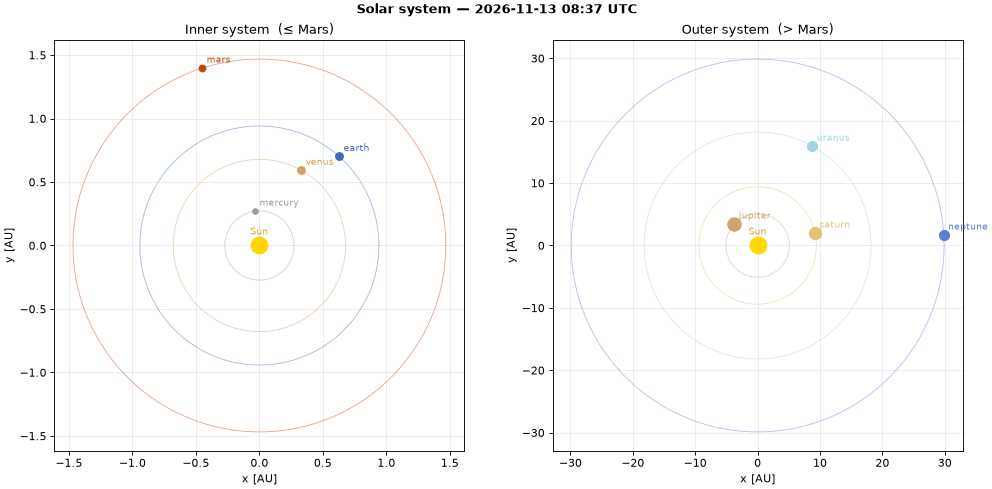

In [2]:
plot_solar_system(Time.now())
plt.show()

## Step 1 — Trans-Lunar Coast

A spacecraft leaves a 400 km parking orbit with one burn, the trans-lunar injection
(TLI), and then coasts under the gravity of Earth, the Moon and the Sun. Its speed is
chosen so that the Moon swings it around and sends it back to Earth with no further
burn. This is a free-return trajectory, the path Apollo flew.

The filter's state is **x** = (position, velocity), six numbers. The measurement **z**
is the position alone: a tracking fix every 3 minutes with a standard deviation of
5 km (`track_km`). Velocity is never measured. The EKF infers it from how the fixes
move, using the gravity model as its prediction.

Here the Moon moves on a circle. Step 1b uses its real position.

In [3]:
moon = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0, track_km=5.0, n_sub=4)
dt_moon = 180.0 / 1e3                               # filter step: 180 s, in ks
r0 = R_EARTH + 400 * KM                             # 400 km parking orbit [Mm]
a_tx = 0.5 * (r0 + D_MOON)                          # ellipse that reaches the Moon's distance
v_tli = np.sqrt(GM_EARTH * (2.0 / r0 - 1.0 / a_tx)) + 0.034   # speed after the burn [km/s], tuned for the free return
x0 = np.array([[r0], [0], [0], [0], [v_tli], [0]])
P0 = np.diag([(50 * KM) ** 2] * 3 + [0.01 ** 2] * 3)          # standard deviations: 50 km and 10 m/s

moon.initial_state(x0, P0=P0)
flight = moon.sample(7.5 * DAY, process_noise=False)   # 7.5 days: out and back
est = moon.filter(flight.zk)

# Splashdown: the first time the radius drops below Earth's after the lunar flyby.
radius_Mm = np.linalg.norm(np.asarray(flight.xk)[:, :3], axis=1)
farthest = int(radius_Mm[:int(4 * DAY / dt_moon)].argmax())   # farthest point, near the Moon
splashdown_k = int(farthest + np.argmax(radius_Mm[farthest:] < R_EARTH))
print(f"Splashdown at t = {splashdown_k * dt_moon / DAY:.2f} d")

# The same launch with the Moon removed, to show what the lunar flyby changes.
kepler_twin = TransLunarModel(moon_phase_deg=133.0, sun_phase_deg=60.0, dt_s=180.0,
                              bodies=("earth",), n_sub=4)
kepler_twin.initial_state(x0, P0=P0)
kepler = kepler_twin.sample(10.5 * DAY, process_noise=False)

moon.plot(est, sample=flight, interactive=True, frames=30, kepler=kepler, nmax=splashdown_k)

Splashdown at t = 6.65 d


### Step 1b — Real Moon Geometry and the Trans-Lunar Launch Window

`use_ephemeris=True` places the Moon and the Sun where they really are at the chosen
`epoch`.

`lunar_porkchop` then scans departure dates and flight times. For each pair it finds
the Earth-centred orbit that reaches the Moon in that time, and adds two speeds: the
injection burn from the 400 km orbit, and the arrival speed relative to the Moon,
which the lunar-orbit insertion (LOI) burn has to remove. Contours of this total
against date and flight time make a porkchop plot, named after its shape.

In [4]:
moon_eph = TransLunarModel(dt_s=180.0, track_km=5.0, n_sub=4,
                           use_ephemeris=True, epoch="2026-11-06")
moon_eph.initial_state(x0, P0=P0)                      # same injection as Step 1
flight_eph = moon_eph.sample(5.5 * DAY, process_noise=False)
est_eph = moon_eph.filter(flight_eph.zk)
moon_eph.plot(est_eph, sample=flight_eph, interactive=True)

cheapest departure: 2026-12-27 | flight time 5.0 d | injection burn 3.08 km/s | arrival speed at the Moon 0.82 km/s


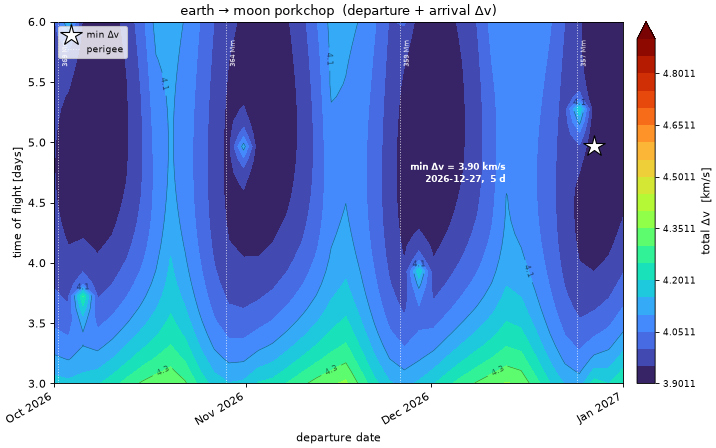

In [5]:
lunar_grid = lunar_porkchop(start="2026-10-01", end="2027-01-01", n_dep=40, tof_days=(3, 6), n_tof=30)
lbest = lunar_grid["best"]
print("cheapest departure:", lbest["dep_date"].iso[:10],
      "| flight time %.1f d | injection burn %.2f km/s | arrival speed at the Moon %.2f km/s"
      % (lbest["tof_days"], lbest["dv_depart_kms"], lbest["dv_arrive_kms"]))
plot_porkchop(lunar_grid)
plt.show()

#### Reading the Lunar Porkchop

The pattern repeats once a month, but it is shallow: the total changes by about 5 %
between the best and the worst day. The injection burn is nearly the same every day.
What changes is the arrival speed relative to the Moon.

The scan always departs from the same point of the parking orbit. Once per lunar
orbit (27.3 days) the Moon arrives roughly on the opposite side of Earth from that
point, and this gives the gentlest approach. The dotted lines mark the Moon's
perigees, its closest points to Earth, with their distances. The distance itself
matters little for the cost.

A real mission also chooses where on the parking orbit it burns, which removes most
of this pattern.

## Step 2 — Earth to Mars: A First Estimate With the Hohmann Transfer

The Hohmann transfer joins two circular orbits in the same plane by half an ellipse:
one burn to leave the inner orbit, one to match the outer orbit on arrival. It is the
cheapest two-burn transfer, and a formula gives its Δv and its time of flight.
`hohmann_transfer` uses each planet's mean distance from the Sun, its semi-major
axis, as the orbit radius.

The transfer only works if Mars is at the far end of the ellipse when the spacecraft
gets there. That alignment repeats once per synodic period, the time Earth takes to
lap Mars. Missing a launch window costs a wait of about two years.

Each Δv printed here is a hyperbolic excess speed, v∞: the speed relative to the
planet that is left once the spacecraft has climbed out of the planet's gravity.
Mission designers also quote its square, C3. The burn itself is a different number,
because it is made in a low parking orbit, where the spacecraft already moves at the
orbital speed v_orbit and still has to escape:

$$v_{\rm burn} = \sqrt{v_\infty^2 + v_{\rm esc}^2} - v_{\rm orbit}$$

with v_esc the escape speed at that altitude. Step 2b prints both numbers.

In [6]:
hohmann = hohmann_transfer("earth", "mars")
for key, value in hohmann.items():
    is_time = hasattr(value, "iso")
    formatted = value.iso[:16] if is_time else round(value, 3) if isinstance(value, float) else value
    print(f"{key:24s}: {formatted}")

departure               : earth
target                  : mars
a1_AU                   : 1.001
a2_AU                   : 1.524
dv_depart_kms           : 2.94
dv_arrive_kms           : 2.645
dv_total_kms            : 5.585
tof_days                : 258.977
phase_angle_deg         : 44.3
synodic_period_days     : 781.406
next_departure          : 2026-12-08 01:00


## Step 2b — Launch Window: The Porkchop Scan (Lambert)

Real orbits are ellipses, tilted against each other, so the next step uses Lambert's
problem: given two positions and a flight time, find the orbit that joins them.

`porkchop` solves it on a grid of departure dates and flight times, from Earth's real
position to Mars's real position, and adds the excess speeds at departure and at
arrival. The cheapest grid point gives the departure date and the spacecraft's
starting state `best["x0"]` for the cruise.

The second cell picks the launch hour at Kennedy Space Center at which Earth's
rotation points most nearly along the departure direction, and prints how much speed
the rotation then contributes.

best departure: 2026-10-28 | flight time 311 d
departure v∞ 3.05 km/s (C3 9.3 km²/s²)  →  burn from a 400 km orbit 3.60 km/s


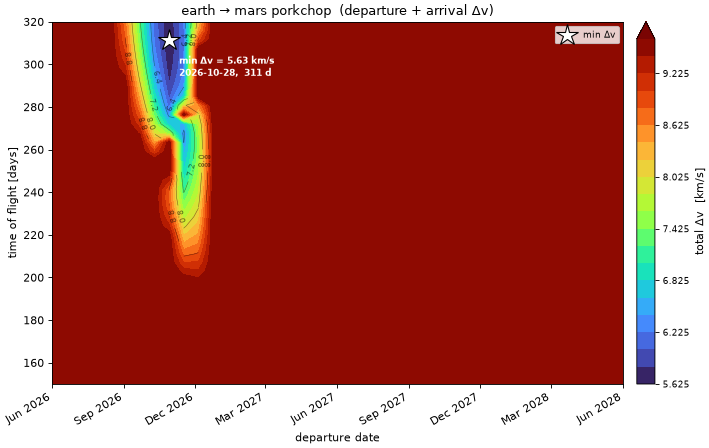

In [7]:
grid = porkchop("earth", "mars", start="2026-06-01", end="2028-06-01",
                n_dep=40, tof_days=(150, 320), n_tof=40)
best = grid["best"]

v_inf = best["v_inf_kms"]                              # excess speed leaving Earth [km/s]
r_park = R_EARTH + 400 * KM                            # 400 km parking orbit [Mm]
burn = np.sqrt(v_inf**2 + 2 * GM_EARTH / r_park) - np.sqrt(GM_EARTH / r_park)
print("best departure:", best["dep_date"].iso[:10], "| flight time %.0f d" % best["tof_days"])
print("departure v∞ %.2f km/s (C3 %.1f km²/s²)  →  burn from a 400 km orbit %.2f km/s"
      % (v_inf, best["c3_km2s2"], burn))

plot_porkchop(grid)
plt.show()

In [8]:
# Best time of day from a launch site (needs network access for Earth-orientation data).
try:
    site_best = best_departure("earth", "mars", start="2026-06-01", end="2028-06-01",
                               n_dep=40, tof_days=(150, 320), n_tof=40, site="Kennedy Space Center")
    print("launch from %s at %s UTC  (Earth's rotation adds %.3f km/s)"
          % (site_best["site"], site_best["launch_time"].iso[11:16], site_best["rotation_assist_kms"]))
except Exception as exc:
    print("launch-site lookup skipped (offline):", type(exc).__name__)

launch from Kennedy Space Center at 05:46 UTC  (Earth's rotation adds 0.364 km/s)


## Step 2c — N-Body EKF Cruise: Earth to Mars

The Lambert orbit assumes the Sun is the only source of gravity. The cruise model
adds the pull of Mercury, Venus, Jupiter and Saturn, so the spacecraft slowly drifts
off the Lambert orbit. Earth and Mars are left out: the model covers the cruise
between them, not the departure and the arrival.

State and measurement are as in Step 1, now centred on the Sun. The filter estimates
position and velocity from position fixes alone: one fix every 12 hours with a
standard deviation of 20 km (`track_Mm=0.02`). They stand in for the range and
Doppler tracking of the Deep Space Network (DSN).

The cell prints the filter's position error next to σ, the filter's own estimate of
that error (the square root of the position part of **P**). In a consistent filter
the two are of the same size.

In [9]:
def report(truth_xk, est):
    """Print the filter's position error and its own estimate of it, sigma, in km."""
    err = np.linalg.norm(np.asarray(truth_xk)[:, :3] - np.asarray(est.xk)[:, :3], axis=1) * 1e3
    sigma = np.sqrt(np.trace(np.asarray(est.Pk)[:, :3, :3], axis1=1, axis2=2)) * 1e3
    print("position error: mean %.0f km, final %.0f km   |   filter σ: mean %.0f km, final %.0f km"
          % (err.mean(), err[-1], sigma.mean(), sigma[-1]))

tof = best["tof_days"]
cruise = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                             dt_s=43200.0, track_Mm=0.02)
P0 = np.diag([1.0] * 3 + [1e-4] * 3)             # standard deviations: 1 Mm (1,000 km) and 0.01 km/s
cruise.initial_state(best["x0"].reshape(-1, 1), P0=P0)
trip = cruise.sample(tof * DAY, process_noise=False)
est = cruise.filter(trip.zk)
report(trip.xk, est)
cruise.plot(est, sample=trip, interactive=True, frames=30)

position error: mean 21 km, final 7 km   |   filter σ: mean 26 km, final 26 km


## Step 2d — Trajectory Correction Manoeuvres (TCMs)

Two things push the spacecraft off target. The launch never delivers exactly the
planned velocity (the injection error), and the planets' pull bends the path away
from the Lambert orbit. Small burns during the cruise, the trajectory correction
manoeuvres, remove the resulting miss at Mars.

Early burns are cheap. A velocity change Δv made a time t_rem before arrival moves
the arrival point by about

$$\Delta r_{\rm arr} \approx \Delta v \times t_{\rm rem}$$

so 1 m/s applied 175 days out shifts it by 1 m/s × 175 d × 86,400 s/d ≈ 15,100 km,
and the same 1 m/s five days out by only 430 km. The schedule therefore has a burn
soon after launch, two trims, and a last one a month before arrival:

| TCM | Day | Purpose |
|-----|-----|---------|
| 1 | 5 | removes the injection error while the leverage is greatest |
| 2, 3 | 30, 90 | trim what the planets' pull has added since |
| 4 | 280 | final aim, about a month before arrival |

At each of these times `TrajectoryControlManeuver` solves Lambert's problem from the
current position to Mars's position at arrival, and burns the difference between the
velocity that orbit needs and the current velocity, up to 50 m/s per burn. Because
Lambert's problem knows only the Sun, the planets' pull after a burn leaves a small
miss for the next burn to remove.

The spacecraft is a generic small probe: 1,200 kg at launch, 600 kg of it
propellant, with one 22 N hydrazine thruster of specific impulse (Isp) 220 s. For
scale, the first correction of Mars Reconnaissance Orbiter was 7.8 m/s
([Spaceflight Now, 2005](https://spaceflightnow.com/news/n0508/25mrotcm1/)).

The cell flies the true spacecraft twice, without and with the corrections, and
prints how far each misses Mars. In this first pass the burns are computed from the
true state.

In [10]:
mc = InterplanetaryModel("earth", "mars", epoch=best["dep_date"], span_days=tof + 20,
                         dt_s=43200.0, control=True, track_Mm=0.02)
dt = 0.5 * DAY                                   # filter step: 12 h [ks]
N = int(round(tof * DAY / dt))                   # number of steps to arrival
arrival = best["dep_date"] + TimeDelta(N * dt * 1e3, format="sec")
mars_arr = body_state("mars", arrival)[0]        # the target: Mars at arrival [Mm]

rng = np.random.default_rng(7)
injection_error = rng.normal(0, 0.002, 3)        # km/s: standard deviation 2 m/s per axis
x0 = best["x0"] + np.r_[np.zeros(3), injection_error]
print("injection error: %.1f m/s" % (np.linalg.norm(injection_error) * 1e3))

tcm = TrajectoryControlManeuver(
    mc, mars_arr, N * dt,
    tcm_days=[5.0, 30.0, 90.0, 280.0],
    dry_mass_kg=mc.SPACECRAFT_DRY_MASS_KG, wet_mass_kg=mc.SPACECRAFT_WET_MASS_KG,
    Isp_s=220.0, thrust_N=22.0,
    max_dv_kms=0.050,                            # at most 50 m/s per burn
)

def fly(x0, controller=None):
    """Propagate the true spacecraft to arrival, with the controller's burns if one is given."""
    x = np.asarray(x0, float).ravel()
    path = [x]
    for i in range(N):
        u = controller(x, np.eye(6), i * dt) if controller is not None else None
        x = mc.f(x, u=u, t=i * dt).ravel()
        path.append(x)
    return np.array(path)

hist_nom = fly(x0)                               # no corrections
hist_cor = fly(x0, tcm)                          # with corrections

miss_nom = np.linalg.norm(hist_nom[-1, :3] - mars_arr) * 1e3   # km
miss_cor = np.linalg.norm(hist_cor[-1, :3] - mars_arr) * 1e3
print("arrival miss without TCMs: %8.0f km" % miss_nom)
print("arrival miss with TCMs   : %8.0f km" % miss_cor)
print()
tcm.summary()

injection error: 0.8 m/s
arrival miss without TCMs:   115808 km
arrival miss with TCMs   :      227 km

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=    4.42 m/s  burn= 240.9 s  Δm=  2.46 kg  m_after=1197.54 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=    0.43 m/s  burn=  23.3 s  Δm=  0.24 kg  m_after=1197.31 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=    0.42 m/s  burn=  23.1 s  Δm=  0.24 kg  m_after=1197.07 kg  TOF_rem=  222 d
  TCM-4   t= 280.0 d  Δv=    8.26 m/s  burn= 448.5 s  Δm=  4.57 kg  m_after=1192.50 kg  TOF_rem=   32 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=   13.53 m/s   Δm=  7.50 kg   propellant left: 592.50 kg


### The Filter in the Loop

No navigator knows the true state. Now the EKF tracks the corrected flight from noisy
fixes, starting from the planned state without the injection error, and the same
controller computes each burn again from the filter's estimate.

The filter applies its own burn in its prediction, while the spacecraft flew the
burn of the first pass. Any difference between the two reaches the filter as a push
it did not expect. If the estimate is good, the two sets of burns agree and the
error stays near σ.

The static plot marks each burn with ×. The replay shows the uncorrected path as a
grey dashed line.

In [11]:
tcm.reset()                                                   # full tanks, no burn fired yet
fixes = hist_cor[1:, :3] + rng.normal(0, 0.02, (N, 3))        # 20 km noise; first fix one step after departure
mc.initial_state(best["x0"].reshape(-1, 1), P0=P0)
est_mc = mc.filter(fixes, uk=tcm)
report(hist_cor[1:], est_mc)
print()
tcm.summary()                                                 # burns computed from the filter's estimate

position error: mean 22 km, final 16 km   |   filter σ: mean 26 km, final 26 km

TCM Summary
────────────────────────────────────────────────────────────────────────────
  TCM-1   t=   5.0 d  Δv=    4.43 m/s  burn= 241.6 s  Δm=  2.46 kg  m_after=1197.54 kg  TOF_rem=  306 d
  TCM-2   t=  30.0 d  Δv=    0.41 m/s  burn=  22.4 s  Δm=  0.23 kg  m_after=1197.31 kg  TOF_rem=  282 d
  TCM-3   t=  90.0 d  Δv=    0.41 m/s  burn=  22.4 s  Δm=  0.23 kg  m_after=1197.08 kg  TOF_rem=  222 d
  TCM-4   t= 280.0 d  Δv=    8.27 m/s  burn= 449.3 s  Δm=  4.58 kg  m_after=1192.50 kg  TOF_rem=   31 d
────────────────────────────────────────────────────────────────────────────
  TOTAL   Δv=   13.53 m/s   Δm=  7.50 kg   propellant left: 592.50 kg


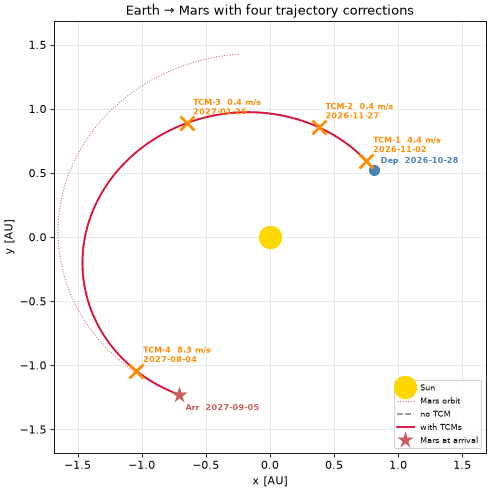

In [12]:
t_dep_str = best["dep_date"].iso[:10]
t_arr_str = arrival.iso[:10]

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0], [0], "o", color="gold", ms=20, label="Sun")
mars_trk = mc.planet_track("mars", N + 1) / AU
ax.plot(mars_trk[:, 0], mars_trk[:, 1], ":", color="indianred", lw=0.9, label="Mars orbit")
ax.plot(hist_nom[:, 0] / AU, hist_nom[:, 1] / AU, "--", color="0.5", lw=1.4, label="no TCM")
ax.plot(hist_cor[:, 0] / AU, hist_cor[:, 1] / AU, color="crimson", lw=1.7, label="with TCMs")
dep_pos = hist_cor[0, :2] / AU
ax.plot([dep_pos[0]], [dep_pos[1]], "o", color="steelblue", ms=10, mec="none", zorder=5)
ax.annotate(f"Dep  {t_dep_str}", dep_pos, xytext=(6, 6), textcoords="offset points",
            fontsize=7, color="steelblue", fontweight="bold")
for burn in tcm.burns:
    burn_idx = int(round(burn["t_ks"] / dt))
    burn_pos = hist_cor[burn_idx, :2] / AU
    burn_date_str = (best["dep_date"] + TimeDelta(float(burn["t_ks"]) * 1e3, format="sec")).iso[:10]
    ax.plot([burn_pos[0]], [burn_pos[1]], "x", color="darkorange", ms=13, mew=2.5, zorder=6)
    ax.annotate("TCM-%d  %.1f m/s\n%s" % (burn["tcm_idx"], burn["dv_ms"], burn_date_str),
                burn_pos, xytext=(6, 8), textcoords="offset points",
                fontsize=7, color="darkorange", fontweight="bold")
mars_pos = mars_arr[:2] / AU
ax.plot([mars_pos[0]], [mars_pos[1]], "*", color="indianred", ms=16, mec="none", zorder=5,
        label="Mars at arrival")
ax.annotate(f"Arr  {t_arr_str}", mars_pos, xytext=(6, -14), textcoords="offset points",
            fontsize=7, color="indianred", fontweight="bold")
lim = 1.15 * np.abs(hist_cor[:, :2] / AU).max()
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal", adjustable="box")
ax.autoscale(False)
ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=7.5)
ax.set_title("Earth → Mars with four trajectory corrections")
plt.show()

# Replay: the filter's estimate, the fixes and the burns.
trip_mc = KalmanRecord(xk=hist_cor, zk=fixes)
burns_for_plot = [(int(round(burn["t_ks"] / dt)), burn["dv_vec_kms"]) for burn in tcm.burns]
mc.plot(est_mc, sample=trip_mc, interactive=True, frames=30,
        burns=burns_for_plot, no_burn=hist_nom)

## Step 3 — Earth to Jupiter: Scaling to the Outer Solar System

Jupiter orbits at 5.2 astronomical units (AU) from the Sun, Mars at 1.5 AU. The same
three steps, a Hohmann estimate, a porkchop scan and an EKF cruise, now describe a
flight of almost three years.

Launch windows come more often than for Mars, because Earth laps slow Jupiter in
little more than a year.

The filter gets one fix per day with a standard deviation of 500 km (`track_Mm=0.5`).

Earth → Jupiter Hohmann:  Δv_total 14.43 km/s   flight time 999 days   synodic period 399 days
best departure: 2028-12-12 | flight time 1010 d | Δv_total 14.73 km/s


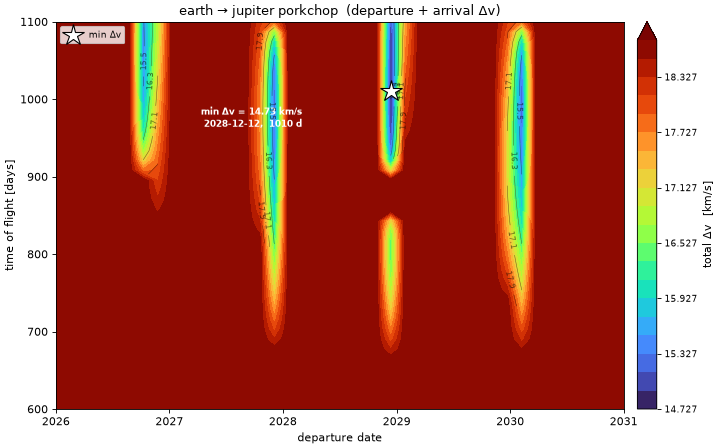

In [13]:
h_jup = hohmann_transfer("earth", "jupiter")
print("Earth → Jupiter Hohmann:  Δv_total %.2f km/s   flight time %.0f days   synodic period %.0f days"
      % (h_jup["dv_total_kms"], h_jup["tof_days"], h_jup["synodic_period_days"]))

grid_jup = porkchop("earth", "jupiter", start="2026-01-01", end="2031-01-01",
                    n_dep=40, tof_days=(600, 1100), n_tof=40)
best_jup = grid_jup["best"]
print("best departure:", best_jup["dep_date"].iso[:10],
      "| flight time %.0f d | Δv_total %.2f km/s" % (best_jup["tof_days"], best_jup["dv_total_kms"]))
plot_porkchop(grid_jup)
plt.show()

position error: mean 286 km, final 200 km   |   filter σ: mean 361 km, final 358 km


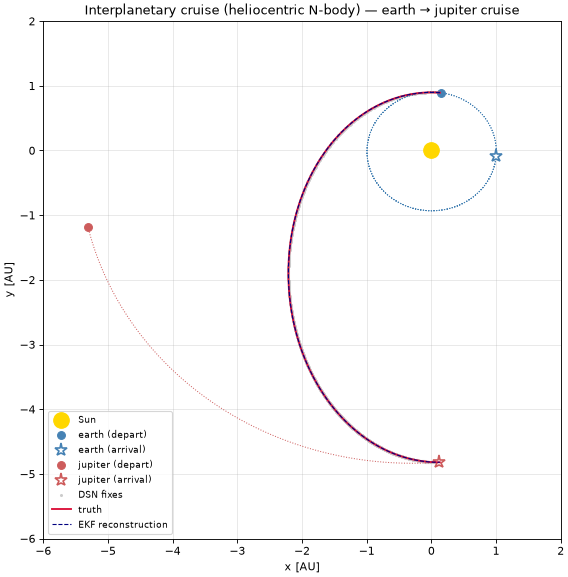

In [14]:
cruise_jup = InterplanetaryModel("earth", "jupiter", epoch=best_jup["dep_date"],
                                 span_days=best_jup["tof_days"] + 60,
                                 perturbers=("mercury", "venus", "mars", "saturn"),
                                 dt_s=86400.0, track_Mm=0.5)
cruise_jup.initial_state(best_jup["x0"].reshape(-1, 1), P0=P0)
trip_jup = cruise_jup.sample(best_jup["tof_days"] * DAY, process_noise=False)
est_jup = cruise_jup.filter(trip_jup.zk)
report(trip_jup.xk, est_jup)

cruise_jup.plot(est_jup, sample=trip_jup, xlim=(-6, 2), ylim=(-6, 2))
plt.show()

cruise_jup.plot(est_jup, sample=trip_jup, interactive=True, frames=30)

## Step 4 — Gravity Assist: Jupiter as a Stepping Stone to Saturn

When a spacecraft flies past a planet, the planet's gravity turns its velocity.
Relative to the planet, the speed is the same before and after. Relative to the Sun,
the spacecraft can leave faster, at no cost in propellant, because the planet itself
is moving. Voyager 1, Voyager 2 and Cassini all reached Saturn this way.

### Step 4a — Analytic Estimate: The Hohmann Chain

`hohmann_sequence(["earth", "jupiter", "saturn"])` adds a Hohmann transfer from Earth
to Jupiter and one from Jupiter to Saturn, and counts only the first burn and the
last. The total is lower than for the direct Hohmann transfer, but it is an
optimistic bound, for two reasons. The slow second leg makes the trip about twice as
long. And the chain reaches Jupiter with one excess speed and leaves with a much
smaller one, which a flyby cannot do: it turns the excess velocity without changing
its size. Step 4c repeats the calculation with real orbits and with that constraint.

In [15]:
hohmann_chain = hohmann_sequence(["earth", "jupiter", "saturn"])
direct_hohmann = hohmann_transfer("earth", "saturn")
print(f"Direct Earth→Saturn Hohmann : Δv = {hohmann_chain['dv_direct_kms']:.2f} km/s  "
      f"flight time = {direct_hohmann['tof_days'] / 365.25:.1f} yr")
print(f"Earth→Jupiter→Saturn chain  : Δv = {hohmann_chain['dv_total_kms']:.2f} km/s  "
      f"flight time = {hohmann_chain['tof_days'] / 365.25:.1f} yr")
for leg in hohmann_chain["legs"]:
    print(f"  {leg['departure']:8s} → {leg['target']:8s}: "
          f"v∞ leaving = {leg['dv_depart_kms']:.2f} km/s  "
          f"v∞ arriving = {leg['dv_arrive_kms']:.2f} km/s  "
          f"flight time = {leg['tof_days']:.0f} d")

Direct Earth→Saturn Hohmann : Δv = 15.73 km/s  flight time = 6.0 yr
Earth→Jupiter→Saturn chain  : Δv = 10.33 km/s  flight time = 12.7 yr
  earth    → jupiter : v∞ leaving = 8.79 km/s  v∞ arriving = 5.64 km/s  flight time = 999 d
  jupiter  → saturn  : v∞ leaving = 1.79 km/s  v∞ arriving = 1.54 km/s  flight time = 3655 d


### Step 4b — The Slingshot Geometry at Jupiter

Seen from Jupiter, the spacecraft comes in on a hyperbola with excess speed v∞,
swings around the planet and leaves with the same v∞ in a new direction. The closer
it passes, the more its path bends. For a closest-approach radius r_p the turn angle
is

$$\delta = 2 \arcsin\frac{1}{1 + r_p v_\infty^2 / \mu_J}$$

with μ_J Jupiter's gravitational parameter (G times its mass). Seen from the Sun, the
spacecraft's velocity is Jupiter's velocity plus this excess velocity. Turning the
excess velocity toward Jupiter's direction of motion therefore makes the spacecraft
faster.

The cell takes the arrival of the Hohmann transfer of Step 3, where the spacecraft
is slower than Jupiter and is caught up by it. It passes 280,000 km above the cloud
tops, about where Voyager 1 passed, and `gravity_assist` returns the largest gain
this turn allows. A more distant flyby turns the path less and gains less: Cassini
passed Jupiter at about 10 million km (Step 6).

In [16]:
# Hohmann arrival at Jupiter, both orbits taken as circles in one plane.
R_E, R_J = h_jup["a1_AU"] * AU, h_jup["a2_AU"] * AU
v_arrival = np.sqrt(GM_SUN * (2 / R_J - 2 / (R_E + R_J)))     # spacecraft speed at Jupiter's orbit [km/s]
v_jupiter = np.sqrt(GM_SUN / R_J)                             # Jupiter's orbital speed [km/s]

assist = gravity_assist(
    v_in_helio=np.array([v_arrival, 0., 0.]),
    v_planet_helio=np.array([v_jupiter, 0., 0.]),
    planet="jupiter",
    h_periapsis_km=280_000.0,
)
print(f"excess speed v∞            : {assist['v_inf_mag']:.2f} km/s")
print(f"turn angle                 : {assist['turn_angle_deg']:.0f}°")
print(f"speed relative to the Sun  : {assist['v_helio_in']:.2f} → {assist['v_helio_out']:.2f} km/s  "
      f"(gain +{assist['dv_gain_kms']:.2f} km/s)")

plot_gravity_assist(assist, planet="jupiter")

excess speed v∞            : 5.64 km/s
turn angle                 : 134°
speed relative to the Sun  : 7.41 → 17.43 km/s  (gain +10.02 km/s)


### Step 4c — Two-Leg Porkchop: Earth to Jupiter to Saturn

The slingshot needs Saturn to be in the right place when the spacecraft leaves
Jupiter. Jupiter laps Saturn only every 20 years, so good windows are rare: Voyager
launched in 1977, Cassini in 1997. The cell uses a window around 2038.

For one departure date, `flyby_porkchop` scans the flight time to Jupiter (tof₁) and
from Jupiter to Saturn (tof₂), with the real planet positions. At each grid point it
solves both Lambert arcs and checks the flyby. The turn must be possible without
passing closer than 200,000 km, and a difference between the incoming and outgoing
excess speed is charged as a burn at closest approach. The direct Earth-to-Saturn
scan of the same window is printed for comparison.

A slower second leg arrives at Saturn more gently. The cheapest point therefore sits
at the longest tof₂ the scan allows: the upper end of the grid is the mission's
patience.

direct       (departure 2038-12-11): v∞ leaving 10.69 + v∞ arriving 5.82 = 16.50 km/s   flight time 8.7 yr
via Jupiter  (departure 2038-10-19): v∞ leaving 10.02 + flyby burn 0.00 + v∞ arriving 3.24 = 13.26 km/s   flight time 6.9 yr (tof₁ 724 d, tof₂ 1800 d)


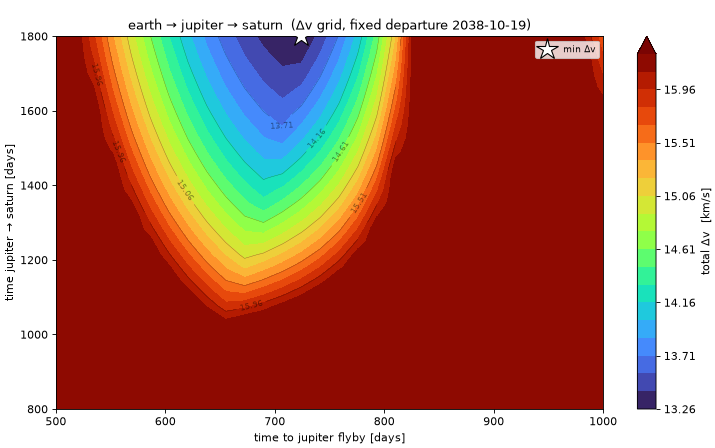

In [17]:
window = dict(start="2038-01-01", end="2039-06-01")
launch = porkchop("earth", "jupiter", n_dep=40, tof_days=(500, 1100), n_tof=40, **window)["best"]
direct = porkchop("earth", "saturn", n_dep=40, tof_days=(1500, 3500), n_tof=40, **window)["best"]

flyby_grid = flyby_porkchop(
    "earth", "jupiter", "saturn", launch["dep_date"],
    tof1_range=(500, 1000), tof2_range=(800, 1800),
    n_tof1=30, n_tof2=30, h_min_km=200_000.0,
)
flyby_best = flyby_grid["best"]
print(f"direct       (departure {direct['dep_date'].iso[:10]}): "
      f"v∞ leaving {direct['dv_depart_kms']:.2f} + v∞ arriving {direct['dv_arrive_kms']:.2f} "
      f"= {direct['dv_total_kms']:.2f} km/s   flight time {direct['tof_days'] / 365.25:.1f} yr")
print(f"via Jupiter  (departure {flyby_best['dep_date'].iso[:10]}): "
      f"v∞ leaving {flyby_best['dv_depart_kms']:.2f} + flyby burn {flyby_best['dv_flyby_kms']:.2f} "
      f"+ v∞ arriving {flyby_best['dv_arrive_kms']:.2f} = {flyby_best['dv_total_kms']:.2f} km/s   "
      f"flight time {(flyby_best['tof1_days'] + flyby_best['tof2_days']) / 365.25:.1f} yr "
      f"(tof₁ {flyby_best['tof1_days']:.0f} d, tof₂ {flyby_best['tof2_days']:.0f} d)")
plot_flyby_porkchop(flyby_grid)
plt.show()

### Step 4d — Two-Leg Trajectory (Interactive)

The two Lambert arcs of the cheapest grid point, with the planets moving. Use the
slider to follow the spacecraft past Jupiter and on to Saturn.

In [18]:
plot_two_leg(flyby_best)

## Step 5 — Propellant Budget, Burn Duration and Filter Uncertainty

Back to the Mars cruise of Step 2d. The rocket equation gives the mass left after a
burn, and the thrust F gives how long the burn lasts:

$$m_{\rm after} = m_{\rm before}\, e^{-\Delta v / (I_{\rm sp}\, g_0)} \qquad\qquad t_{\rm burn} = \frac{\Delta m \, I_{\rm sp}\, g_0}{F}$$

where Δm is the propellant burnt and g₀ = 9.81 m/s². One 22 N thruster accelerates a
1,200 kg spacecraft by only about 0.02 m/s², so even a few m/s take minutes. That is
still short against the 12-hour filter step, which is why the model applies each burn
as an instant change of velocity. All four burns together use a small part of the
600 kg of propellant.

The last column is Δv × time remaining, the leverage of Step 2d. The burn on day 280
is the largest, yet it moves the arrival point far less than the smaller burn on
day 5.

The plot shows the filter's position uncertainty σ over the cruise. The burns leave
no mark on it: the filter is told each burn, so a burn adds no uncertainty. σ is set
by the tracking noise and falls as the fixes accumulate.

In [19]:
propellant_kg = mc.SPACECRAFT_WET_MASS_KG - mc.SPACECRAFT_DRY_MASS_KG
print("launch mass %.0f kg, of which propellant %.0f kg" % (mc.SPACECRAFT_WET_MASS_KG, propellant_kg))
print()
for burn in tcm.burns:
    shift_km = burn["dv_ms"] * 1e-3 * burn["tof_rem_days"] * 86400.0     # km/s × s
    print("  TCM-%d  day %5.1f  Δv = %5.2f m/s  burn = %4.0f s  propellant = %4.2f kg  "
          "Δv × time remaining ≈ %7.0f km"
          % (burn["tcm_idx"], burn["t_days"], burn["dv_ms"], burn["burn_s"], burn["prop_kg"], shift_km))
print()
print("total Δv %.2f m/s, propellant used %.2f kg (%.1f %% of the propellant), remaining %.1f kg"
      % (sum(burn["dv_ms"] for burn in tcm.burns), tcm.propellant_consumed_kg,
         100.0 * tcm.propellant_consumed_kg / propellant_kg, tcm.propellant_remaining_kg))

launch mass 1200 kg, of which propellant 600 kg

  TCM-1  day   5.0  Δv =  4.43 m/s  burn =  242 s  propellant = 2.46 kg  Δv × time remaining ≈  117408 km
  TCM-2  day  30.0  Δv =  0.41 m/s  burn =   22 s  propellant = 0.23 kg  Δv × time remaining ≈   10022 km
  TCM-3  day  90.0  Δv =  0.41 m/s  burn =   22 s  propellant = 0.23 kg  Δv × time remaining ≈    7874 km
  TCM-4  day 280.0  Δv =  8.27 m/s  burn =  449 s  propellant = 4.58 kg  Δv × time remaining ≈   22517 km

total Δv 13.53 m/s, propellant used 7.50 kg (1.3 % of the propellant), remaining 592.5 kg


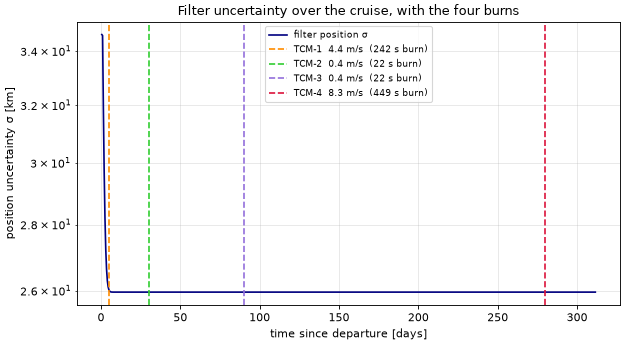

In [20]:
sigma_r = np.sqrt(np.trace(np.asarray(est_mc.Pk)[:, :3, :3], axis1=1, axis2=2)) * 1e3    # km
t_days = (np.arange(len(sigma_r)) + 1) * dt / DAY

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(t_days, sigma_r, color="navy", lw=1.5, label="filter position σ")
for burn, col in zip(tcm.burns, ["darkorange", "limegreen", "mediumpurple", "crimson"]):
    ax.axvline(burn["t_days"], color=col, ls="--", lw=1.5,
               label="TCM-%d  %.1f m/s  (%.0f s burn)" % (burn["tcm_idx"], burn["dv_ms"], burn["burn_s"]))
ax.set_xlabel("time since departure [days]")
ax.set_ylabel("position uncertainty σ [km]")
ax.set_title("Filter uncertainty over the cruise, with the four burns")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Step 6 — Cassini: Replicating the Route to Saturn

Cassini–Huygens left Earth on 15 October 1997 and reached Saturn on 1 July 2004,
by way of four gravity assists:

> Earth → Venus → Venus → Earth → Jupiter → Saturn

| Leg | From | To | Dates | Flight time |
|-----|------|----|-------|-------------|
| 1 | Earth   | Venus   | 1997-10-15 → 1998-04-26 | 193 d |
| 2 | Venus   | Venus   | 1998-04-26 → 1999-06-24 | 424 d |
| 3 | Venus   | Earth   | 1999-06-24 → 1999-08-18 |  54 d |
| 4 | Earth   | Jupiter | 1999-08-18 → 2000-12-30 | 500 d |
| 5 | Jupiter | Saturn  | 2000-12-30 → 2004-07-01 | 1279 d |

Between the two Venus flybys, on 3 December 1998, Cassini fired its main engine for
about 90 minutes and changed its velocity by about 450 m/s. This deep-space manoeuvre
was made far from the Sun, where the spacecraft is slow. It lowered the orbit's
closest point to the Sun, so that Cassini met Venus the second time at a much higher
relative speed.

`chain_lambert` rebuilds the route from the encounter times, which are the mission's
own and are taken as input. Each leg is one Lambert arc, except the Venus-to-Venus
leg, which is two arcs joined on the day of the manoeuvre. Where the manoeuvre
happens is not given: the solver places it so that both Venus flybys are free, with
the smallest burn. For every flyby the function reports two different things:

- the gravity Δv, the change of the spacecraft's velocity relative to the Sun. The
  planet delivers it, and it costs nothing.
- the burn needed, the difference between the excess speed arriving and the excess
  speed leaving. Gravity cannot change that speed, so whatever remains here is
  propellant the rebuilt route would have to spend.

The second cell prints the result next to the mission's figures. The model is still a
simplification: each planet acts at a single point and instant (the patched-conic
approximation), the ephemeris is approximate, and only the Venus leg has a
manoeuvre, so the Earth and Jupiter flybys keep a small mismatch.

Mission figures: flyby altitudes from ESA,
[Getting to Saturn](https://sci.esa.int/web/cassini-huygens/-/31240-getting-to-saturn);
the manoeuvre from ESA,
[Deep-space manoeuvre completed](https://sci.esa.int/web/cassini-huygens/-/12007-cassini-huygens-deep-space-manoeuvre-completed);
the gravity Δv at Venus and Earth from NASA's
[Cassini timeline](https://science.nasa.gov/mission/cassini/the-journey/timeline/);
the launch energy from Fantino et al., [arXiv:2001.04357](https://arxiv.org/abs/2001.04357).

In [21]:
cassini_sequence = ["earth", "venus", "venus", "earth", "jupiter", "saturn"]
cassini_dates = [
    Time("1997-10-15 08:43"),   # launch
    Time("1998-04-26 13:52"),   # Venus 1 flyby
    Time("1999-06-24 20:30"),   # Venus 2 flyby
    Time("1999-08-18 03:28"),   # Earth flyby
    Time("2000-12-30 10:05"),   # Jupiter flyby
    Time("2004-07-01 02:48"),   # Saturn orbit insertion
]
manoeuvre = {1: Time("1998-12-03 06:45")}    # on leg 2 (index 1), at the middle of the burn

legs = chain_lambert(cassini_sequence, cassini_dates, dsm=manoeuvre)

print(f"{'flyby':<9}{'date':<12}{'v∞ in → out [km/s]':>19}{'gravity Δv [km/s]':>20}"
      f"{'burn needed [km/s]':>20}{'altitude [km]':>16}")
for before, leg in zip(legs, legs[1:]):          # each leg after the first starts with a flyby
    print(f"{leg['departure']:<9}{leg['dep_date'].iso[:10]:<12}"
          f"{before['v_inf_arr_kms']:>9.2f} → {leg['v_inf_dep_kms']:<7.2f}"
          f"{leg['dv_gravity_kms']:>20.2f}{leg['dv_burn_kms']:>20.2f}{leg['flyby_altitude_km']:>16,.0f}")
print()
print("deep-space manoeuvre on %s: %.0f m/s, at %.2f AU from the Sun"
      % (legs[1]["dsm_date"].iso[:10], legs[1]["dv_dsm_kms"] * 1e3, np.linalg.norm(legs[1]["r_dsm"]) / AU))
print("total flight time: %.0f days (%.1f years)"
      % (sum(leg["tof_days"] for leg in legs), sum(leg["tof_days"] for leg in legs) / 365.25))

flyby    date         v∞ in → out [km/s]   gravity Δv [km/s]  burn needed [km/s]   altitude [km]
venus    1998-04-26       6.00 → 6.00                   6.86                0.00             714
venus    1999-06-24       9.43 → 9.43                   6.78                0.00             463
earth    1999-08-18      16.02 → 15.84                  5.84                0.18             628
jupiter  2000-12-30      10.62 → 10.44                  1.98                0.18      11,011,922

deep-space manoeuvre on 1998-12-03: 530 m/s, at 1.57 AU from the Sun
total flight time: 2451 days (6.7 years)


In [22]:
venus1, venus2, earth, jupiter = legs[1:]        # the legs that start with a flyby

rows = [   # quantity, this notebook, the mission
    ("launch energy C3 [km²/s²]",       legs[0]["v_inf_dep_kms"] ** 2,   16.6),
    ("Venus-1 altitude [km]",           venus1["flyby_altitude_km"],     284),
    ("Venus-1 gravity Δv [km/s]",       venus1["dv_gravity_kms"],        7),
    ("deep-space manoeuvre [m/s]",      venus1["dv_dsm_kms"] * 1e3,      450),
    ("Venus-2 altitude [km]",           venus2["flyby_altitude_km"],     603),
    ("Earth altitude [km]",             earth["flyby_altitude_km"],      1173),
    ("Earth gravity Δv [km/s]",         earth["dv_gravity_kms"],         5.5),
    ("Jupiter altitude [million km]",   jupiter["flyby_altitude_km"] / 1e6, 9.72),
]
print(f"{'':<32}{'notebook':>10}{'mission':>10}")
for name, ours, real in rows:
    print(f"{name:<32}{ours:>10.4g}{real:>10g}")

print()
print("gravity Δv of the four flybys, added up: %.1f km/s (this notebook's route)"
      % sum(leg["dv_gravity_kms"] for leg in legs))

# The same dates with a single arc from Venus to Venus, that is, without the manoeuvre.
single = chain_lambert(cassini_sequence, cassini_dates)
print("without the manoeuvre: burn needed %.2f km/s at Venus-1 and %.2f km/s at Venus-2, "
      "passing %.0f km and %.0f km above Venus"
      % (single[1]["dv_burn_kms"], single[2]["dv_burn_kms"],
         single[1]["flyby_altitude_km"], single[2]["flyby_altitude_km"]))

                                  notebook   mission
launch energy C3 [km²/s²]            16.38      16.6
Venus-1 altitude [km]                714.5       284
Venus-1 gravity Δv [km/s]            6.857         7
deep-space manoeuvre [m/s]           529.6       450
Venus-2 altitude [km]                462.8       603
Earth altitude [km]                  627.6      1173
Earth gravity Δv [km/s]              5.839       5.5
Jupiter altitude [million km]        11.01      9.72

gravity Δv of the four flybys, added up: 21.4 km/s (this notebook's route)
without the manoeuvre: burn needed 0.95 km/s at Venus-1 and 2.49 km/s at Venus-2, passing 9356 km and 16180 km above Venus


Launch energy, gravity Δv, the size of the manoeuvre and the Jupiter altitude come
out within about 20 % of the mission. The flyby altitudes have the right order of
magnitude, hundreds of kilometres at Venus and Earth, but each is off by up to a
factor 2.5. An altitude follows from the turn angle, and a small error in the
velocities changes it a lot.

The last line shows why the manoeuvre is needed. With a single arc from Venus to
Venus, the same dates could only be flown with large burns at both Venus flybys.

In [23]:
# Left: the inner solar system with the Venus and Earth flybys. Right: the whole route.
plot_multi_leg(legs,
               title="Cassini (1997–2004):  Earth → Venus → Venus → Earth → Jupiter → Saturn",
               extra_planets=("mars",),
               frames=30,
               zoom_lim="auto")

## Further Reading

- **Optical navigation.** Probes also navigate by camera, which gives the direction
  to a planet or a star but not the distance. Replace the position fix by a direction
  measurement and watch the uncertainty grow along the line of sight.
- **Other routes.** Change the dates in Step 6, or move the manoeuvre, and see what
  the flybys then need.
- **Back to the pad.** Notebook 06, Rocket Science, covers liftoff, guided ascent and
  the gimballed landing.